In [1]:
from collections.abc import Callable, Sequence
from pathlib import Path

import cv2
import pandas as pd
from torch import nn

from dataset.augmentation import (
    AugmentationConfig,
    MotionBlurConfig,
    RandomMotionBlur,
)
from dataset.augmentation.debug import plot_trajectory_motion_blur_preview
from dataset.viz.ball_localization_visualizer import BallLocalizationVisualizer
from model.cnn import CNN
from model.engine.experiment_config import ExperimentConfig
from model.engine.ball_data_module import BallDataModule
from model.engine.ball_localization_trainer import BallLocalizationTrainer
from model.engine.model_checkpoint import ModelCheckpoint
from model.eval.ball_location_evaluator import BallLocalizationEvaluator

In [2]:
config = ExperimentConfig(
    raw_data_dir=Path(
        "/home/bugslayer/Documents/research/data/VolleyVision/VballNet/train"
    ),
    processed_data_dir=Path(
        "/home/bugslayer/Documents/research/data/VolleyVision/processed/512x288"
    ),
    checkpoint_path=Path(
        "/home/bugslayer/Documents/research/VolleyVision/notebooks/dataset/ball_model.pth"
    ),
    train_augmentation=AugmentationConfig(
        motion_blur=MotionBlurConfig(
            probability=0.30,
            kernel_size_range=(3, 15),
            strength_bias=1.5,
            trajectory_displacement_range=(1.0, 30.0),
        )
    ),
)

data_module = BallDataModule(config).prepare_data()
manifest_df = data_module.manifest_df

train_df = data_module.frame_table("train")
val_df = data_module.frame_table("val")
test_df = data_module.frame_table("test")

train_dataset = data_module.dataset("train")
val_dataset = data_module.dataset("val")
test_dataset = data_module.dataset("test")

train_loader = data_module.dataloader("train")
val_loader = data_module.dataloader("val")
test_loader = data_module.dataloader("test")

display(data_module.split_summary())

build_vballnet_manifest
Found 15 possible match directories


/home/bugslayer/Documents/research/VolleyVision/dataset/preprocess/vballnet.py:185: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(videos)



Dataset summary
----------------
matches: 15
csv_files: 70
valid_videos: 70
missing_videos: 0
invalid_videos: 0
annotations: 23350
split_dataset
preprocess_frames


Processing videos: 100%|██████████| 70/70 [02:37<00:00,  2.25s/it]


,frames,videos,visible_frames,invisible_frames
split,,,,
train,16574,49,15637,937
val,4451,10,4260,191
test,2325,11,2156,169


In [3]:
batch = next(iter(train_loader))

print("image:", tuple(batch["image"].shape))
print("target:", tuple(batch["target"].shape))
print("visibility:", tuple(batch["visibility"].shape))

image: (16, 3, 288, 512)
target: (16, 1, 288, 512)
visibility: (16,)


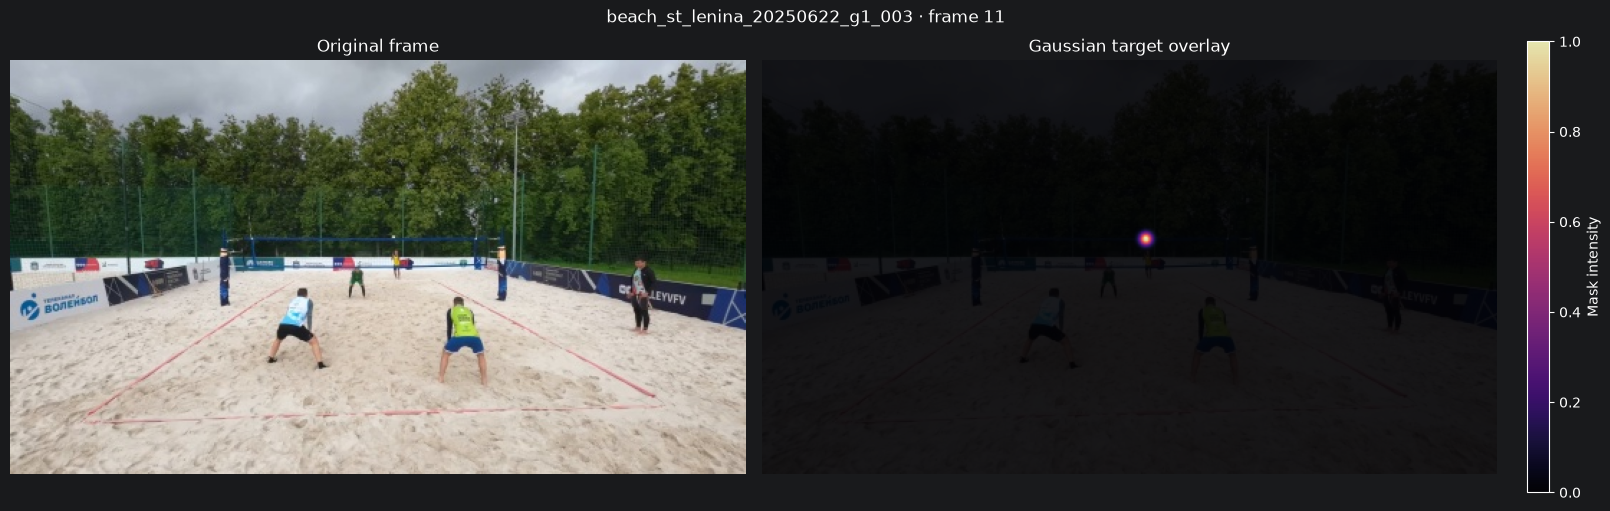

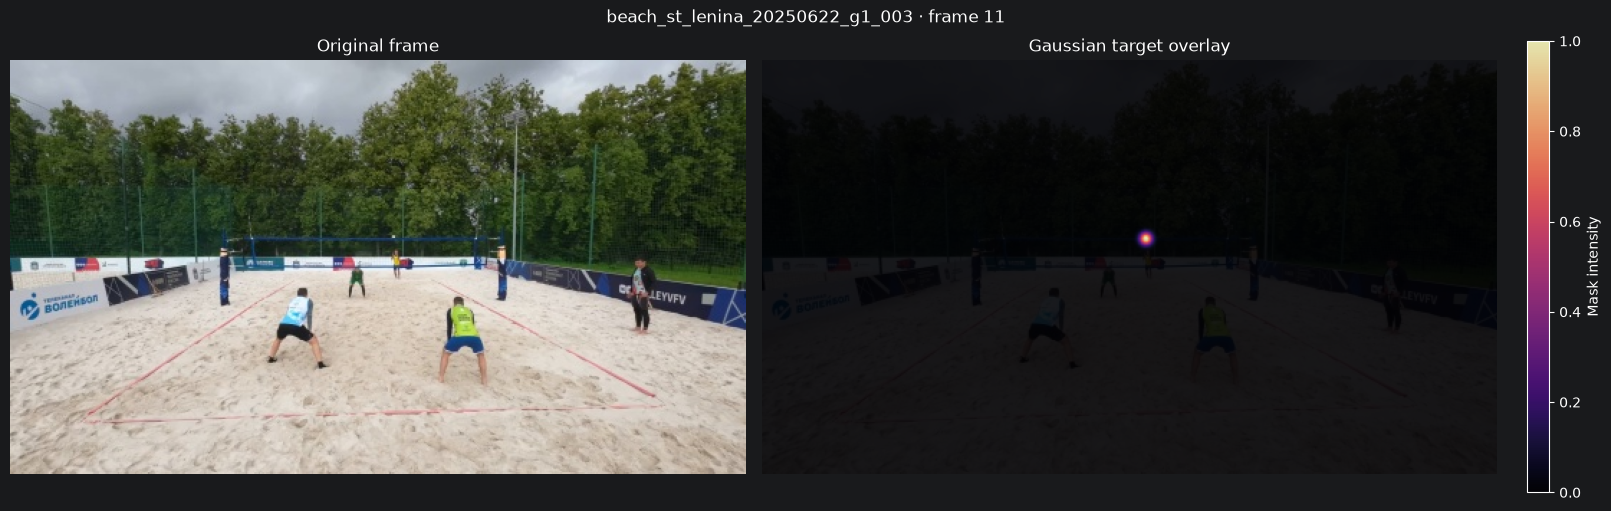

In [4]:
visualizer = BallLocalizationVisualizer()
visualizer.plot_visible_target(
    train_dataset,
    train_df,
    visible_rank=min(10, int(train_df["visibility"].sum()) - 1),
)

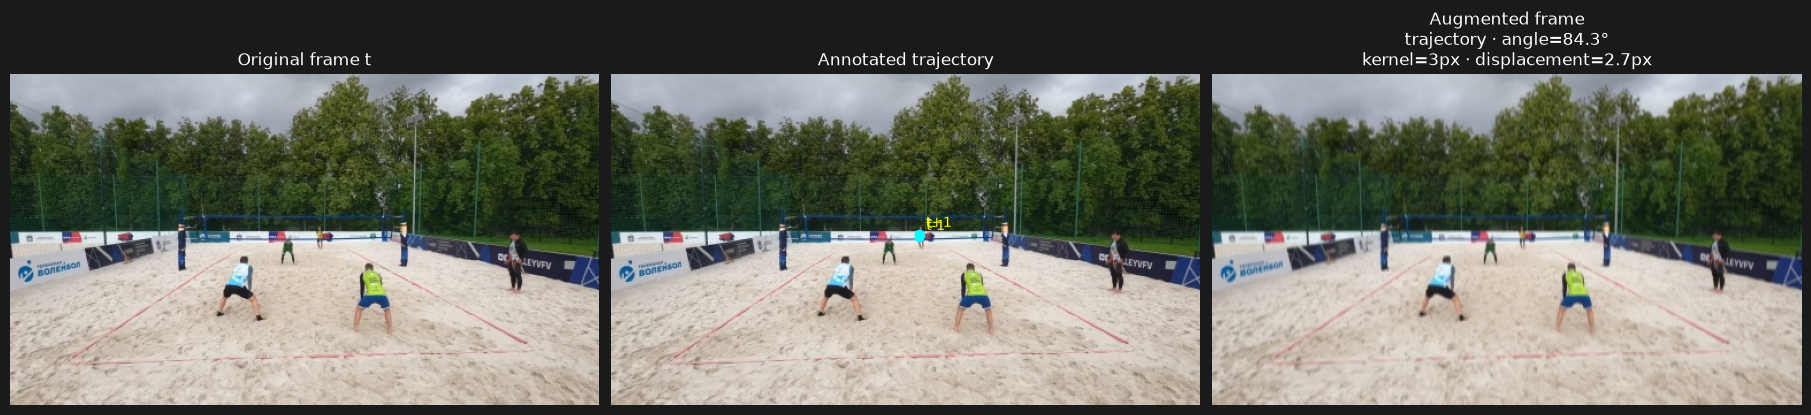

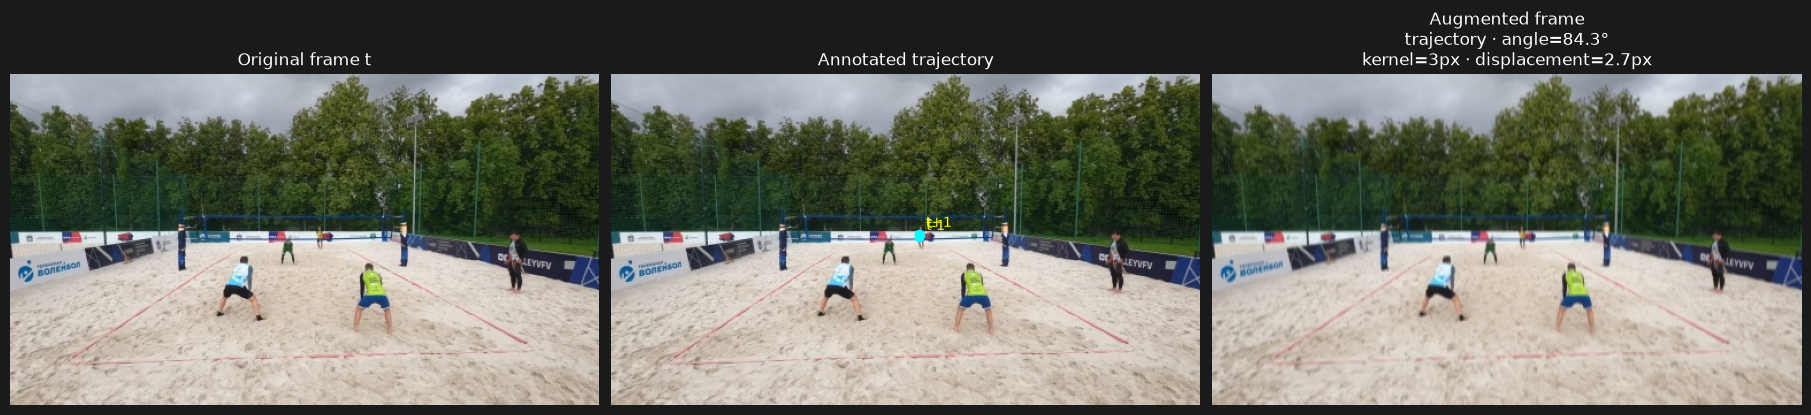

In [5]:
motion_blur_config = config.train_augmentation.motion_blur
if motion_blur_config is None:
    raise RuntimeError("Motion blur is not enabled in the experiment config.")

preview_augmentation = RandomMotionBlur(motion_blur_config)
preview_index = None
preview_context = None
for candidate_index in train_df.index[train_df["visibility"].eq(1)]:
    candidate_context = train_dataset.augmentation_context(
        int(candidate_index)
    )
    candidate_parameters = preview_augmentation.select_parameters(
        candidate_context
    )
    if (
        candidate_parameters is not None
        and candidate_parameters.source == "trajectory"
    ):
        preview_index = int(candidate_index)
        preview_context = candidate_context
        break

if preview_index is None or preview_context is None:
    raise ValueError("No complete moving-ball trajectory was found.")

preview_path = train_df.iloc[preview_index]["frame_path"]
preview_bgr = cv2.imread(preview_path)
if preview_bgr is None:
    raise RuntimeError(f"Could not read {preview_path}")
preview_rgb = cv2.cvtColor(preview_bgr, cv2.COLOR_BGR2RGB)

plot_trajectory_motion_blur_preview(
    image=preview_rgb,
    context=preview_context,
    config=motion_blur_config,
    seed=7,
)

In [6]:
# Swap this factory to train and evaluate another compatible model.
model_factory: Callable[[], nn.Module] = CNN

device = config.resolved_device()
model = model_factory()
evaluator = BallLocalizationEvaluator(config.thresholds)
trainer = BallLocalizationTrainer(
    model=model,
    evaluator=evaluator,
    device=device,
    learning_rate=config.learning_rate,
)
checkpoint = ModelCheckpoint(config.checkpoint_path)

print(f"Using device: {device}")

Using device: cuda


In [7]:
model, history = trainer.fit(
    train_loader=train_loader,
    val_loader=data_module.dataloader("val_small"),
    epochs=config.epochs,
    full_val_loader=val_loader,
    full_validation_interval=config.validation_interval,
)

display(history.tail())

Epoch 1/51 | train_loss=0.000198 | val_loss=0.000132 | mean_dist=48.20px | median_dist=2.83px | PCK@5=0.622 | PCK@10=0.629 | PCK@20=0.638


Epoch 5/51 | train_loss=0.000051 | val_loss=0.000089 | mean_dist=33.19px | median_dist=1.00px | PCK@5=0.765 | PCK@10=0.766 | PCK@20=0.773


Epoch 10/51 | train_loss=0.000035 | val_loss=0.000072 | mean_dist=36.34px | median_dist=1.00px | PCK@5=0.781 | PCK@10=0.782 | PCK@20=0.785


Epoch 15/51 | train_loss=0.000027 | val_loss=0.000065 | mean_dist=26.02px | median_dist=1.00px | PCK@5=0.810 | PCK@10=0.812 | PCK@20=0.818


Epoch 20/51 | train_loss=0.000022 | val_loss=0.000088 | mean_dist=30.64px | median_dist=1.00px | PCK@5=0.777 | PCK@10=0.779 | PCK@20=0.782


Epoch 25/51 | train_loss=0.000019 | val_loss=0.000069 | mean_dist=26.74px | median_dist=1.00px | PCK@5=0.807 | PCK@10=0.810 | PCK@20=0.818


... (3 outputs left out)

Epoch 45/51 | train_loss=0.000012 | val_loss=0.000071 | mean_dist=30.17px | median_dist=1.00px | PCK@5=0.815 | PCK@10=0.818 | PCK@20=0.820


Epoch 50/51 | train_loss=0.000011 | val_loss=0.000069 | mean_dist=29.59px | median_dist=1.00px | PCK@5=0.819 | PCK@10=0.822 | PCK@20=0.823


Epoch 51/51 | train_loss=0.000011 | val_loss=0.000086 | mean_dist=29.88px | median_dist=1.00px | PCK@5=0.805 | PCK@10=0.808 | PCK@20=0.810


,epoch,train_loss,val_loss,mean_distance_px,median_distance_px,pck_5,pck_10,pck_20
46,47,0.000012,NaN,NaN,NaN,NaN,NaN,NaN
47,48,0.000011,NaN,NaN,NaN,NaN,NaN,NaN
48,49,0.000012,NaN,NaN,NaN,NaN,NaN,NaN
49,50,0.000011,0.000069,29.587124,1.0,0.819484,0.822066,0.823239
50,51,0.000011,0.000086,29.879471,1.0,0.805399,0.807981,0.810329


In [8]:
saved_checkpoint = checkpoint.save(model)
print(f"Saved checkpoint to {saved_checkpoint}")

Saved checkpoint to /home/bugslayer/Documents/research/VolleyVision/notebooks/dataset/ball_model.pth


## Held-out test results

`BallLocalizationEvaluator` uses the same decoding and metric accumulation for validation and testing. Metrics are aggregated per frame (rather than averaging per-batch medians), and prediction rows remain available for qualitative inspection.

In [9]:
split_summary = data_module.split_summary()
display(split_summary)

,frames,videos,visible_frames,invisible_frames
split,,,,
train,16574,49,15637,937
val,4451,10,4260,191
test,2325,11,2156,169


In [10]:
test_model = checkpoint.load(model_factory(), device)
test_model.eval()

CNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil

In [11]:
test_metrics_dict, test_predictions_df = evaluator.evaluate(
    model=test_model,
    data_loader=test_loader,
    device=device,
    frame_table=test_df,
    description="Testing",
)
test_metrics = pd.Series(test_metrics_dict, name="value")
worst_predictions = (
    test_predictions_df
    .dropna(subset=["distance_px"])
    .nlargest(10, "distance_px")
)

display(test_metrics.to_frame())
display(
    worst_predictions[
        [
            "video_id",
            "frame",
            "target_x",
            "target_y",
            "predicted_x",
            "predicted_y",
            "distance_px",
            "peak_value",
        ]
    ]
)

,value
frames,2325.000000
heatmap_mse,0.000085
visible_frames,2156.000000
invisible_frames,169.000000
mean_distance_px,33.955879
median_distance_px,1.414214
pck_5,0.742579
pck_10,0.749072
pck_20,0.758349


,video_id,frame,target_x,target_y,predicted_x,predicted_y,distance_px,peak_value
2116,obl_man_orlovski_ogau_0001_odd0_30fps_mirror,90,472.0,181.0,42,100,437.562567,0.018097
2115,obl_man_orlovski_ogau_0001_odd0_30fps_mirror,89,449.0,161.0,46,96,408.208280,0.016148
2113,obl_man_orlovski_ogau_0001_odd0_30fps_mirror,87,398.0,126.0,24,235,389.560008,0.012937
2112,obl_man_orlovski_ogau_0001_odd0_30fps_mirror,86,369.0,107.0,24,235,367.979619,0.012486
2020,pobead_4m-2w_1place_00003,124,0.0,0.0,345,124,366.607419,0.022143
2114,obl_man_orlovski_ogau_0001_odd0_30fps_mirror,88,425.0,143.0,73,111,353.451553,0.011287
1915,pobead_4m-2w_1place_00003,19,0.0,0.0,280,126,307.043971,0.416967
1916,pobead_4m-2w_1place_00003,20,0.0,0.0,279,122,304.507800,0.017538
76,4m2w_20250620_transmash_3_far_001,76,214.0,190.0,465,63,281.300551,0.013701
165,5m1g_lokomotiv_rus_berhovie_001,80,166.0,134.0,417,237,271.311629,0.188057


### Qualitative error inspection

The reusable visualizer plots the largest visible-ball errors. Green circles are ground truth and yellow crosses are model predictions.

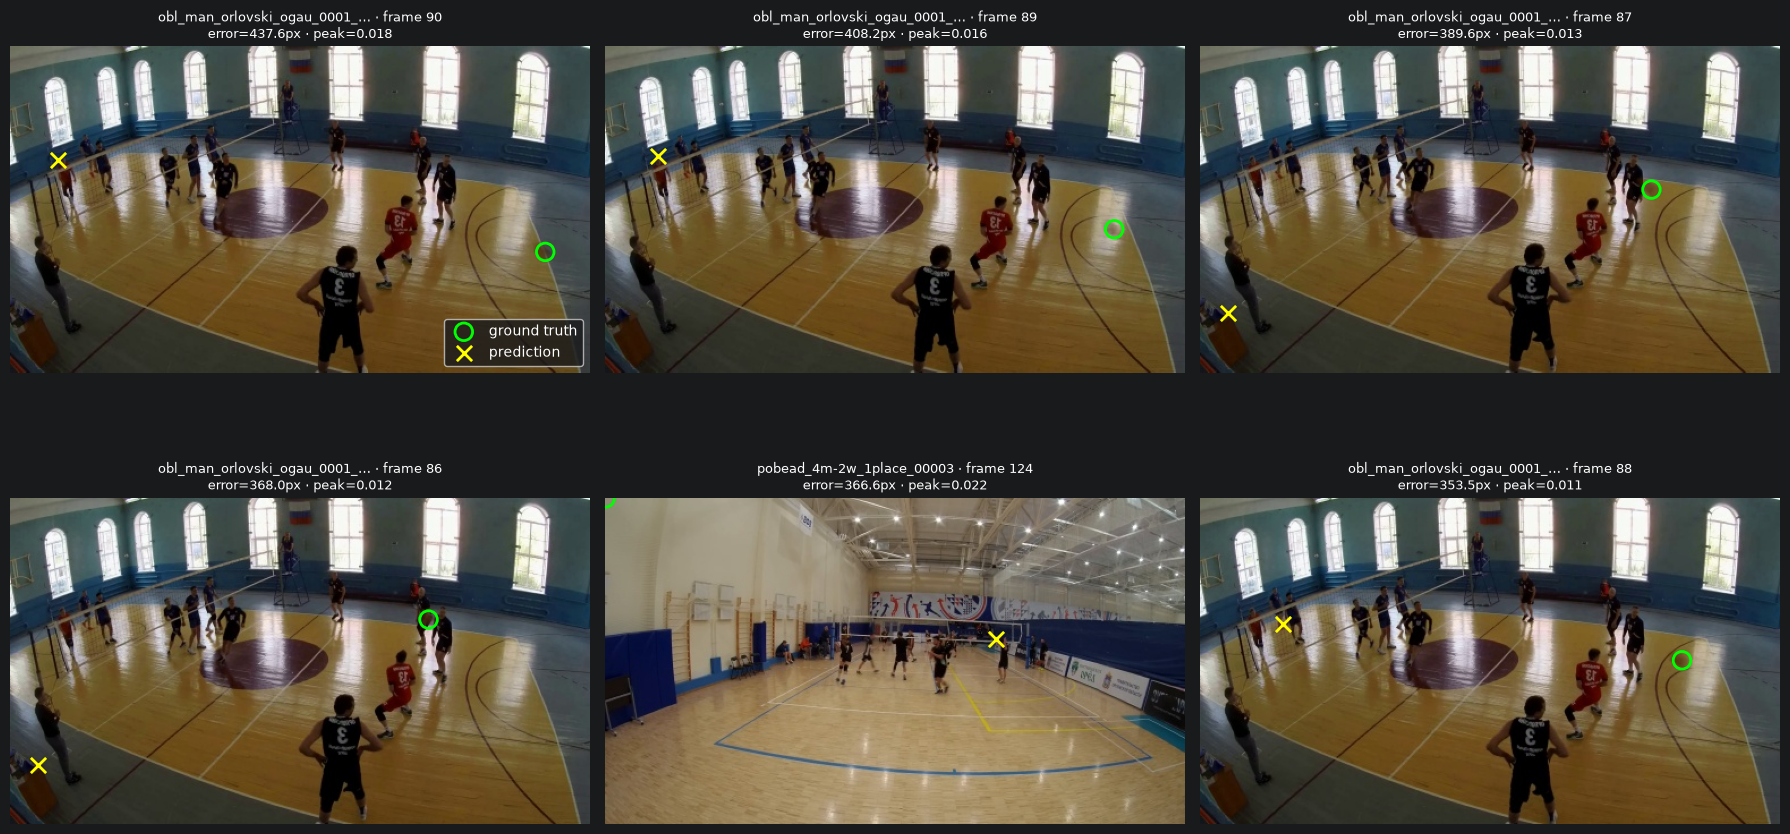

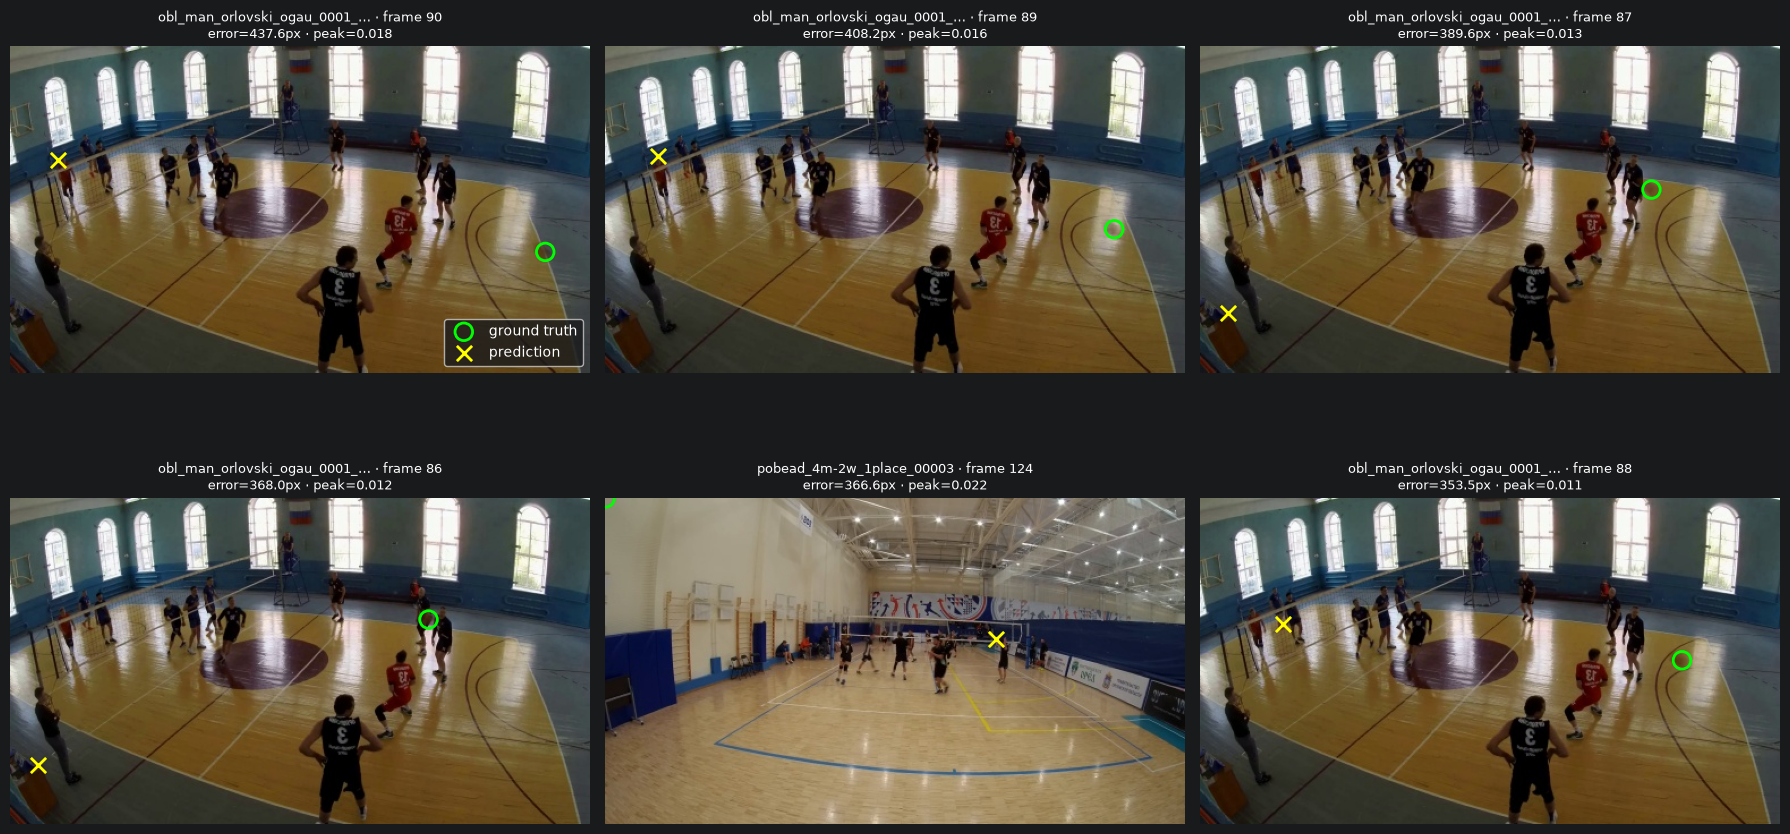

In [12]:
visualizer.plot_errors(
    dataset=test_dataset,
    predictions=test_predictions_df,
    count=6,
    columns=3,
)